# DSC 411/511 Project
# Notebook 05: RQ3: Do Building and Policy Features Form Meaningful Groups?

**Class topics:** Lecture 08 (k-means, hierarchical clustering, naming clusters, "are these groups real?"),
Lecture 09 (density, DBSCAN), Lecture 10 (silhouette, Davies-Bouldin, noise baseline, stability),
Lecture 16 (autoencoders, latent space, **t-SNE**), Lecture 04 (PCA for plotting).

---

> **RQ3. If we ignore the damage outcome, do the building and policy features form groups that mean
> something?**

**The rule from Lecture 08, 0.1.** We cluster on building and policy facts **only**. Payment and damage are
left out on purpose. If we clustered on damage, the groups would of course differ by damage, and that would be
circular. We look at the outcomes **only after** the groups are fixed.

We then judge the groups with the three questions from Lectures 08 and 10:
1. Is the silhouette clearly better than on random data of the same shape?
2. Does the same structure come back with a different seed and a different sample?
3. Can we name the clusters in words an insurance person would use?

---
# Section 0: Setup

In [1]:
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.stats import chi2_contingency

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 180)

claims = load_clean_claims()
print(f'Claims available: {len(claims):,}')

Claims available: 253,124


---
# Section 1: Which Columns, and Why Not All of Them (Lecture 08, 0.1)

Clustering on 50 columns gives groups nobody can describe. We pick 14 facts an underwriter would use to
describe a flood policy: what is insured, for how much, how it is built, and where it sits on the flood map.

In [2]:
claims['log_deductible'] = np.log10(claims['building_deductible_usd'])
claims['is_single_family'] = (claims['occupancy_group'] == 'single_family').astype(int)
claims['is_condo_or_multi_unit'] = claims['occupancy_group'].isin(['condo_association', 'unit_in_multi_unit_building',
                                                                   'multi_family_5plus', 'multi_family_2to4']).astype(int)
claims['has_basement'] = claims['basement_group'].isin(['finished_basement', 'unfinished_basement']).astype(int)
claims['number_of_floors'] = claims['floors_group'].map({'one_floor': 1, 'two_floors': 2, 'three_plus_floors': 3, 'split_level': 2,
                                                         'manufactured_home': 1, 'townhouse_3plus': 3}).fillna(1)
claims['in_V_zone'] = (claims['flood_zone_group'] == 'V_coastal_high_hazard').astype(int)

claims['log_number_of_units'] = np.log10(claims['numberOfUnits'].clip(lower=1))
CLUSTER_FEATURES = [
    'log_building_coverage', 'log_contents_coverage', 'log_deductible', 'log_number_of_units',
    'postFIRMConstructionIndicator', 'building_age_at_loss', 'policy_tenure_years', 'number_of_floors',
    'elevatedBuildingIndicator', 'has_basement', 'in_special_flood_hazard_area', 'in_V_zone',
    'primaryResidenceIndicator', 'is_single_family',
]
check_no_leakage(CLUSTER_FEATURES)
OUTCOMES_FOR_LATER = ['building_paid_flag', 'large_loss_flag', 'amountPaidOnBuildingClaim', 'damage_to_value_ratio']
print('Clustering features:', len(CLUSTER_FEATURES))
print('Held back until Section 11:', OUTCOMES_FOR_LATER)

cluster_sample = claims.sample(20_000, random_state=SEED).reset_index(drop=True)
print(cluster_sample[CLUSTER_FEATURES].describe().T.round(2).to_string())

Clustering features: 14
Held back until Section 11: ['building_paid_flag', 'large_loss_flag', 'amountPaidOnBuildingClaim', 'damage_to_value_ratio']
                                 count   mean    std   min    25%    50%    75%     max
log_building_coverage          20000.0  12.26   0.82  4.62  12.07  12.43  12.43   18.27
log_contents_coverage          20000.0   7.59   5.02  0.00   0.00  10.46  11.51   13.12
log_deductible                 20000.0   3.38   0.33  2.30   3.10   3.30   3.70    4.70
log_number_of_units            20000.0   0.10   0.31  0.00   0.00   0.00   0.00    2.65
postFIRMConstructionIndicator  20000.0   0.33   0.47  0.00   0.00   0.00   1.00    1.00
building_age_at_loss           20000.0  48.06  22.70  0.10  33.15  48.74  61.67  221.25
policy_tenure_years            20000.0   8.33   7.26  0.00   2.27   6.59  12.65   53.36
number_of_floors               20000.0   1.44   0.63  1.00   1.00   1.00   2.00    3.00
elevatedBuildingIndicator      20000.0   0.21   0.41  0.00  

## 1.1 Scaling is not optional (Lecture 08, 0.2)

In [3]:
column_ranges = (cluster_sample[CLUSTER_FEATURES].max() - cluster_sample[CLUSTER_FEATURES].min()).sort_values(ascending=False)
print('Column ranges, widest first:')
print(column_ranges.round(2).to_string())
scaler = StandardScaler().fit(cluster_sample[CLUSTER_FEATURES])
scaled_sample = scaler.transform(cluster_sample[CLUSTER_FEATURES])
print('\nUnscaled, building age (range ~200 years) would decide almost every distance.')

Column ranges, widest first:
building_age_at_loss             221.15
policy_tenure_years               53.36
log_building_coverage             13.65
log_contents_coverage             13.12
log_number_of_units                2.65
log_deductible                     2.40
number_of_floors                   2.00
postFIRMConstructionIndicator      1.00
elevatedBuildingIndicator          1.00
has_basement                       1.00
in_special_flood_hazard_area       1.00
in_V_zone                          1.00
primaryResidenceIndicator          1.00
is_single_family                   1.00

Unscaled, building age (range ~200 years) would decide almost every distance.


---
# Section 2: k-means, Step by Step

k-means repeats two steps until nothing changes:
1. **Assign** each claim to the nearest centroid (Euclidean distance).
2. **Update** each centroid to the mean of its claims.

Each round can only lower the **inertia** (the sum of squared distances to the own centroid), so it always
stops. It can stop in a poor local minimum, so we restart it 20 times (`n_init=20`) and keep the best.

## 2.1 How many clusters? (Lecture 08, Section 1)

 k     inertia  silhouette  davies_bouldin
 2 241466.3768      0.2535          2.0123
 3 212831.7669      0.1651          1.9791
 4 195497.5135      0.1748          1.7636
 5 178873.7815      0.1895          1.6477
 6 165505.5972      0.2042          1.5529
 7 154317.3842      0.1994          1.6147
 8 146179.4913      0.1720          1.5815
 9 139473.8459      0.1730          1.5865
10 135146.7704      0.1760          1.5685


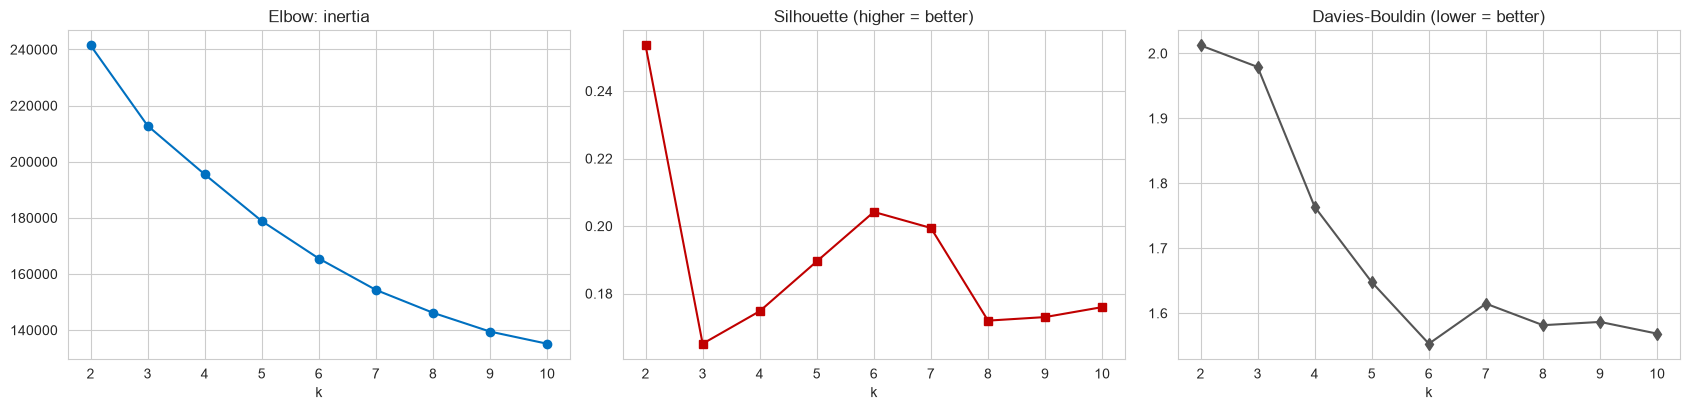

In [4]:
k_values = range(2, 11)
k_rows = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(scaled_sample)
    k_rows.append({'k': k, 'inertia': kmeans.inertia_,
                   'silhouette': silhouette_score(scaled_sample, kmeans.labels_, sample_size=8000, random_state=SEED),
                   'davies_bouldin': davies_bouldin_score(scaled_sample, kmeans.labels_)})
k_table = pd.DataFrame(k_rows)
print(k_table.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].plot(k_table['k'], k_table['inertia'], 'o-', color='#0070C0')
axes[0].set_title('Elbow: inertia')
axes[1].plot(k_table['k'], k_table['silhouette'], 's-', color='#C00000')
axes[1].set_title('Silhouette (higher = better)')
axes[2].plot(k_table['k'], k_table['davies_bouldin'], 'd-', color='#555555')
axes[2].set_title('Davies-Bouldin (lower = better)')
for ax in axes:
    ax.set_xlabel('k')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_choose_k.png', dpi=120)
plt.show()

## 2.2 The noise baseline, done properly: 20 shuffled datasets and the gap statistic (Lecture 10, Section 4)

Every algorithm returns clusters, even on noise. To know if our silhouette is "good", we build **random datasets of
the same shape**: each column is shuffled on its own. This keeps every column's distribution but destroys the links
between columns. Real structure lives in those links.

An earlier version of this notebook used only **3** shuffled datasets. With so few, the noise mean moved enough
between runs to flip the choice between k = 2 and k = 4. Now we use **20 shuffled datasets** for every k from 2 to 10
and two criteria:

1. **Silhouette gap** = real silhouette - mean noise silhouette. We also report how many noise standard deviations
   the real value lies above the noise (a z-score), and whether it beats **all 20** noise datasets.
2. **The gap statistic** (Tibshirani, Walther and Hastie, 2001). It compares the k-means inertia W(k) with the
   inertia of the shuffled data: Gap(k) = mean(log W_noise(k)) - log W(k). The rule picks the **smallest k with
   Gap(k) >= Gap(k+1) - s(k+1)**, where s is the noise standard deviation times sqrt(1 + 1/20). (Tibshirani et al. draw
   the reference data uniformly in a box; with 0/1 flags a box would create values like 0.37, so we use the
   column-shuffled data as the reference, the same idea with the same column distributions.)

In [5]:
NOISE_REPEATS = 20
noise_k_values = list(range(2, 11))
rng = np.random.default_rng(SEED)
noise_rows = []
for repeat in range(NOISE_REPEATS):
    shuffled = scaled_sample.copy()
    for column_index in range(shuffled.shape[1]):
        shuffled[:, column_index] = rng.permutation(shuffled[:, column_index])
    for k in noise_k_values:
        noise_model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(shuffled)
        noise_rows.append({'k': k, 'repeat': repeat, 'noise_silhouette': silhouette_score(shuffled, noise_model.labels_, sample_size=8000, random_state=SEED),
                           'noise_log_inertia': np.log(noise_model.inertia_)})
noise_draws = pd.DataFrame(noise_rows)
noise_table = noise_draws.groupby('k').agg(noise_mean=('noise_silhouette', 'mean'), noise_std=('noise_silhouette', 'std'),
                                           noise_max=('noise_silhouette', 'max'), noise_log_W_mean=('noise_log_inertia', 'mean'),
                                           noise_log_W_std=('noise_log_inertia', 'std')).reset_index()
comparison = k_table.merge(noise_table, on='k')
comparison['real_minus_noise'] = comparison['silhouette'] - comparison['noise_mean']
comparison['z_vs_noise'] = comparison['real_minus_noise'] / comparison['noise_std']
comparison['beats_all_20_noise'] = comparison['silhouette'] > comparison['noise_max']
comparison['gap_statistic'] = comparison['noise_log_W_mean'] - np.log(comparison['inertia'])
comparison['gap_s'] = comparison['noise_log_W_std'] * np.sqrt(1 + 1 / NOISE_REPEATS)
comparison.round(4).to_csv(TABLE_DIR / '05_rq3_k_selection.csv', index=False)
print(comparison[['k', 'silhouette', 'noise_mean', 'noise_std', 'real_minus_noise', 'z_vs_noise', 'beats_all_20_noise',
                  'gap_statistic', 'gap_s']].round(4).to_string(index=False))

 k  silhouette  noise_mean  noise_std  real_minus_noise  z_vs_noise  beats_all_20_noise  gap_statistic  gap_s
 2      0.2535      0.1324     0.0663            0.1211      1.8268               False         0.0739 0.0000
 3      0.1651      0.1162     0.0251            0.0489      1.9530               False         0.1283 0.0048
 4      0.1748      0.1192     0.0173            0.0556      3.2149                True         0.1452 0.0091
 5      0.1895      0.1112     0.0112            0.0784      6.9899                True         0.1739 0.0115
 6      0.2042      0.1152     0.0112            0.0890      7.9129                True         0.1914 0.0100
 7      0.1994      0.1147     0.0106            0.0848      7.9613                True         0.2097 0.0145
 8      0.1720      0.1080     0.0090            0.0640      7.1006                True         0.2234 0.0175
 9      0.1730      0.1030     0.0069            0.0701     10.1964                True         0.2317 0.0114
10      0.

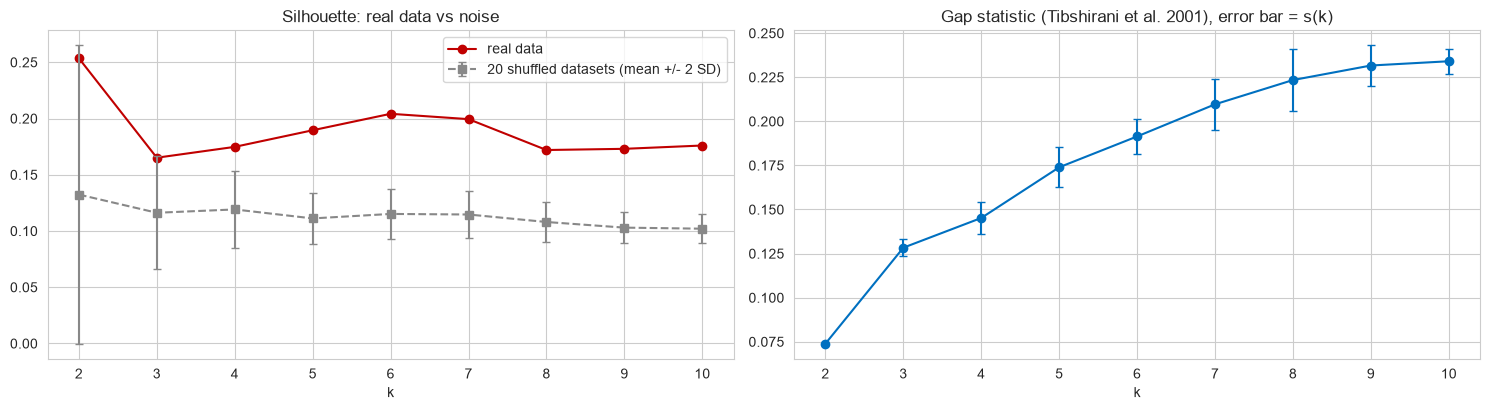

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
axes[0].plot(comparison['k'], comparison['silhouette'], 'o-', color='#C00000', label='real data')
axes[0].errorbar(comparison['k'], comparison['noise_mean'], yerr=2 * comparison['noise_std'], fmt='s--', color='#888888',
                 capsize=3, label='20 shuffled datasets (mean +/- 2 SD)')
axes[0].set_title('Silhouette: real data vs noise')
axes[0].legend()
axes[1].errorbar(comparison['k'], comparison['gap_statistic'], yerr=comparison['gap_s'], fmt='o-', color='#0070C0', capsize=3)
axes[1].set_title('Gap statistic (Tibshirani et al. 2001), error bar = s(k)')
for ax in axes:
    ax.set_xlabel('k')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_noise_baseline_gap.png', dpi=120)
plt.show()

In [7]:
silhouette_gap_best_k = int(comparison.loc[comparison['real_minus_noise'].idxmax(), 'k'])
gap_rule_k = None
for position in range(len(comparison) - 1):
    this_row, next_row = comparison.iloc[position], comparison.iloc[position + 1]
    if this_row['gap_statistic'] >= next_row['gap_statistic'] - next_row['gap_s']:
        gap_rule_k = int(this_row['k'])
        break
gap_rule_text = gap_rule_k if gap_rule_k is not None else 'none in 2-10 (the gap keeps growing)'
print(f'k with the largest silhouette gap over noise : {silhouette_gap_best_k}')
print(f'k chosen by the Tibshirani gap rule          : {gap_rule_text}')

# The design choice: k = 4 gives groups an analyst can use (Lecture 08: clusters must be useful). We keep it only if
# k = 4 is clearly real structure: its silhouette must beat ALL 20 shuffled datasets. Otherwise we follow the data.
K_BY_DESIGN = 4
row_k4 = comparison.loc[comparison['k'] == K_BY_DESIGN].iloc[0]
if row_k4['beats_all_20_noise']:
    CHOSEN_K = K_BY_DESIGN
    choice_reason = (f'k = {K_BY_DESIGN} kept by design: its silhouette {row_k4["silhouette"]:.3f} beats all 20 noise datasets '
                     f'(max {row_k4["noise_max"]:.3f}, z = {row_k4["z_vs_noise"]:.1f})')
else:
    CHOSEN_K = silhouette_gap_best_k
    choice_reason = f'k = {K_BY_DESIGN} does not beat all noise datasets, so we follow the data: k = {CHOSEN_K}'
print('Chosen k =', CHOSEN_K, '->', choice_reason)
kmeans_final = KMeans(n_clusters=CHOSEN_K, n_init=30, random_state=SEED).fit(scaled_sample)
cluster_sample['cluster'] = kmeans_final.labels_
print(cluster_sample['cluster'].value_counts().sort_index().to_string())

k with the largest silhouette gap over noise : 2
k chosen by the Tibshirani gap rule          : 7
Chosen k = 4 -> k = 4 kept by design: its silhouette 0.175 beats all 20 noise datasets (max 0.149, z = 3.2)


cluster
0      785
1    10591
2     3020
3     5604


**Reading the k choice.** The three criteria do not agree, and we say so:
- The **largest silhouette gap** over noise is at **k = 2** (0.254 vs 0.132). But at k = 2 the shuffled data is very
  unstable (noise SD 0.066, maximum 0.314), so k = 2 does **not** beat all 20 noise sets (z = 1.8).
- The **Tibshirani gap rule** picks **k = 7**, but the gap keeps rising up to k = 10 (0.07 -> 0.23), so it has no
  clear elbow.
- From **k = 4 upward every k beats all 20 noise sets**. k = 4: 0.175 vs noise 0.119 +/- 0.017 (max 0.149,
  z = 3.2). k = 5-7 beat noise even more clearly (z about 7-8), and k = 6 has the best silhouette (0.204).

**Decision: we keep k = 4.** It is defensible because it is clearly real structure (above every noise set), and its
four groups are easy to name and use. It is **not** the statistical optimum: k = 6-7 separate the data a little
better. We report this as a design choice, not as "the" number of groups.

---
# Section 3: Naming the Clusters (Lecture 08, Section 3)

We profile each cluster on the original (unscaled) features, and compare it with the overall average.

In [8]:
profile = cluster_sample.groupby('cluster')[CLUSTER_FEATURES].mean()
profile['size_%'] = cluster_sample['cluster'].value_counts(normalize=True).sort_index() * 100
profile['median_coverage_usd'] = cluster_sample.groupby('cluster')['totalBuildingInsuranceCoverage'].median()
profile['top_occupancy'] = cluster_sample.groupby('cluster')['occupancy_group'].agg(lambda s: s.value_counts().index[0])
profile['top_flood_zone'] = cluster_sample.groupby('cluster')['flood_zone_group'].agg(lambda s: s.value_counts().index[0])
profile['top_state'] = cluster_sample.groupby('cluster')['state'].agg(lambda s: s.value_counts().index[0])
print(profile.T.to_string())

cluster                                            0                       1                       2                       3
log_building_coverage                      12.450892               12.056375               12.989366               12.212205
log_contents_coverage                        7.30807                7.576301                4.123665                9.515963
log_deductible                              3.454396                3.416591                3.533696                3.205199
log_number_of_units                          0.21286                0.003747                0.562589                0.006473
postFIRMConstructionIndicator               0.397452                0.001888                0.275166                0.980014
building_age_at_loss                       42.520493               59.512228               49.586955               26.352104
policy_tenure_years                        10.400038                7.414684                9.856758                8.951614


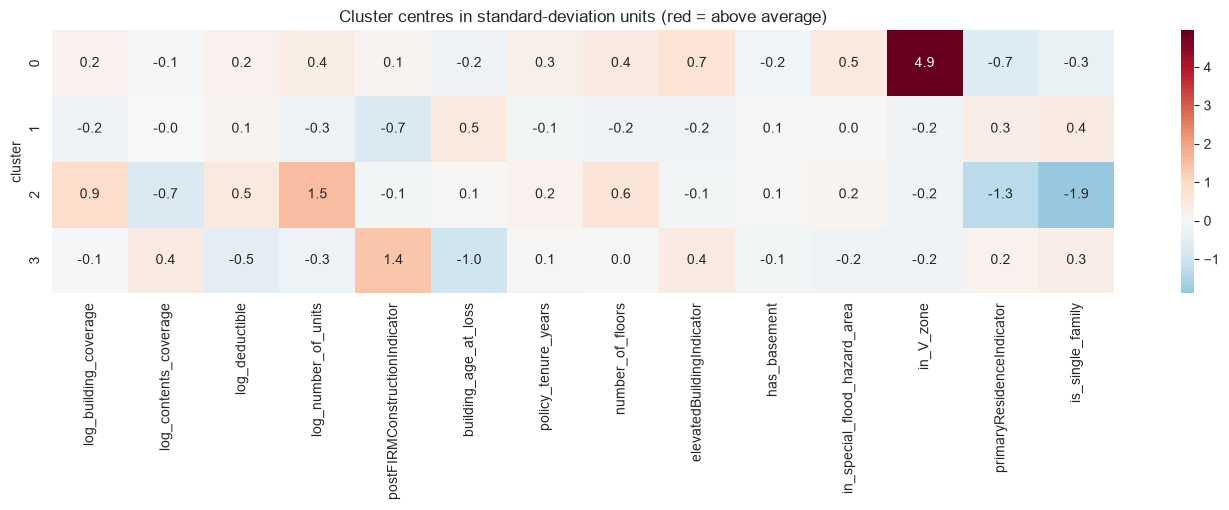

In [9]:
z_profile = pd.DataFrame(kmeans_final.cluster_centers_, columns=CLUSTER_FEATURES)
fig, ax = plt.subplots(figsize=(14, 0.8 * CHOSEN_K + 2))
sns.heatmap(z_profile, cmap='RdBu_r', center=0, annot=True, fmt='.1f', ax=ax)
ax.set_ylabel('cluster')
ax.set_title('Cluster centres in standard-deviation units (red = above average)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_cluster_centres.png', dpi=120)
plt.show()

In [10]:
def describe_cluster(row):
    """Turn a cluster centre (z-scores) into words. Rules are simple and printed, so the reader can check them."""
    words = []
    if row['is_single_family'] < -0.8:
        words.append('condo / multi-unit or commercial')
    elif row['is_single_family'] > 0.3:
        words.append('single-family homes')
    if row['elevatedBuildingIndicator'] > 0.8:
        words.append('elevated')
    if row['in_V_zone'] > 1:
        words.append('V-zone coastal')
    elif row['in_special_flood_hazard_area'] < -0.8:
        words.append('outside the SFHA (zone X)')
    if row['has_basement'] > 1:
        words.append('with basement')
    if row['log_building_coverage'] > 0.8:
        words.append('high coverage')
    elif row['log_building_coverage'] < -0.8:
        words.append('low coverage')
    if row['primaryResidenceIndicator'] < -0.8:
        words.append('second homes / rentals')
    if row['building_age_at_loss'] > 0.6:
        words.append('old buildings')
    elif row['building_age_at_loss'] < -0.6:
        words.append('newer buildings')
    if row['policy_tenure_years'] > 0.8:
        words.append('long-time policyholders')
    return ', '.join(words) if words else 'typical policy'


cluster_names = {cluster: f'C{cluster}: {describe_cluster(row)}' for cluster, row in z_profile.iterrows()}
for name in cluster_names.values():
    print(name)
cluster_sample['cluster_name'] = cluster_sample['cluster'].map(cluster_names)

C0: V-zone coastal
C1: single-family homes
C2: condo / multi-unit or commercial, high coverage, second homes / rentals
C3: single-family homes, newer buildings


---
# Section 4: Hierarchical Clustering and the Dendrogram (Lecture 08, Sections 4-6)

Agglomerative clustering starts with every claim alone and repeatedly **merges the two closest groups**.
"Closest" depends on the **linkage**: Ward merges the pair that increases the within-group variance the least;
average linkage uses the mean pairwise distance; complete linkage uses the largest one. The memory cost grows
with n squared, so we use a 4,000-claim subsample.

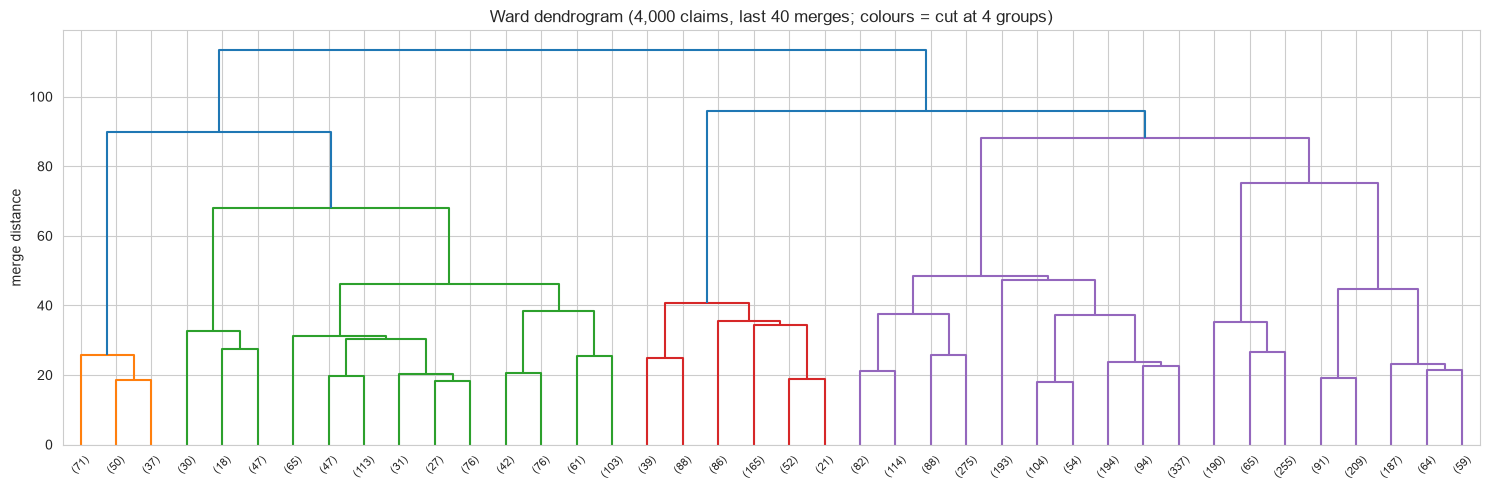

 linkage  silhouette  ARI_vs_kmeans  largest_cluster_%
    ward       0.232          0.321             66.375
 average       0.347          0.062             96.275
complete       0.238          0.251             86.825
  single       0.337          0.107             95.550


In [11]:
hierarchy_index = np.random.default_rng(SEED).choice(len(scaled_sample), 4000, replace=False)
hierarchy_data = scaled_sample[hierarchy_index]
ward_tree = linkage(hierarchy_data, method='ward')
fig, ax = plt.subplots(figsize=(15, 5))
dendrogram(ward_tree, truncate_mode='lastp', p=40, ax=ax, color_threshold=ward_tree[-(CHOSEN_K - 1), 2])
ax.set_title(f'Ward dendrogram (4,000 claims, last 40 merges; colours = cut at {CHOSEN_K} groups)')
ax.set_ylabel('merge distance')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_dendrogram.png', dpi=120)
plt.show()

linkage_rows = []
kmeans_labels_subsample = kmeans_final.labels_[hierarchy_index]
for method in ['ward', 'average', 'complete', 'single']:
    labels = fcluster(linkage(hierarchy_data, method=method), t=CHOSEN_K, criterion='maxclust')
    sizes = np.bincount(labels)[1:]
    linkage_rows.append({'linkage': method, 'silhouette': silhouette_score(hierarchy_data, labels),
                         'ARI_vs_kmeans': adjusted_rand_score(kmeans_labels_subsample, labels),
                         'largest_cluster_%': sizes.max() / len(labels) * 100})
print(pd.DataFrame(linkage_rows).round(3).to_string(index=False))

**Linkage changes the answer (Lecture 08, Section 5).** Single and average linkage tend to produce one giant
cluster plus tiny outlier groups. Ward agrees best with k-means, because both minimise within-group variance.

---
# Section 5: DBSCAN: Is There Density Structure? (Lecture 09)

DBSCAN does not need k. A point is a **core** point if at least `min_samples` points lie within distance `eps`.
Clusters are chains of core points; points that are not reachable are **noise**. We choose `eps` from the
k-distance plot: sort every point's distance to its k-th neighbour and look for the knee.

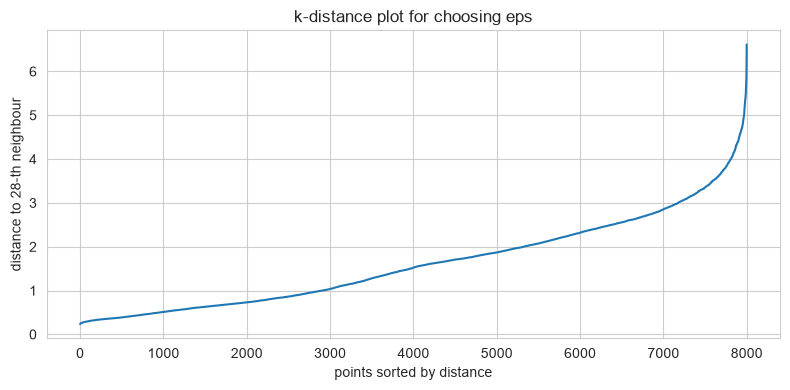

 eps  clusters  noise_%  largest_cluster_%
 0.8        19     61.5               13.1
 1.2        20     49.4               21.1
 1.6        21     34.0               26.3
 2.0        19     21.7               26.8
 2.5         6      9.0               68.1


In [12]:
min_samples = 2 * len(CLUSTER_FEATURES)
neighbour_model = NearestNeighbors(n_neighbors=min_samples).fit(scaled_sample[:8000])
kth_distances = np.sort(neighbour_model.kneighbors(scaled_sample[:8000])[0][:, -1])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(kth_distances)
ax.set_xlabel('points sorted by distance')
ax.set_ylabel(f'distance to {min_samples}-th neighbour')
ax.set_title('k-distance plot for choosing eps')
plt.tight_layout()
plt.show()

dbscan_rows = []
for eps in [0.8, 1.2, 1.6, 2.0, 2.5]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(scaled_sample[:8000])
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    dbscan_rows.append({'eps': eps, 'clusters': n_clusters, 'noise_%': (labels == -1).mean() * 100,
                        'largest_cluster_%': (pd.Series(labels[labels >= 0]).value_counts().max() / len(labels) * 100) if n_clusters else 0})
print(pd.DataFrame(dbscan_rows).round(1).to_string(index=False))

**The honest reading (Lecture 09, Section 7).** With 0/1 flags, the data lives on the corners of a cube. DBSCAN
finds many small, dense "corners" at small eps, and merges everything into one blob at larger eps. The groups
here are **not** separated by empty space. That is why k-means (which only needs centres) is a better tool for
this question.

---
# Section 6: Are These Groups Real? Stability (Lecture 08 Section 7, Lecture 10 Section 5)

In [13]:
seed_labels = [KMeans(n_clusters=CHOSEN_K, n_init=10, random_state=seed).fit_predict(scaled_sample) for seed in range(6)]
seed_ari = [adjusted_rand_score(seed_labels[0], labels) for labels in seed_labels[1:]]
print(f'ARI across 5 other seeds: {np.round(seed_ari, 3)}  (1.0 = identical)')

other_sample = claims.drop(cluster_sample.index, errors='ignore').sample(20_000, random_state=SEED + 1)
other_scaled = StandardScaler().fit_transform(other_sample[CLUSTER_FEATURES])
other_model = KMeans(n_clusters=CHOSEN_K, n_init=20, random_state=SEED).fit(other_scaled)
common_rows = scaler.transform(claims.sample(10_000, random_state=SEED + 2)[CLUSTER_FEATURES])
sample_ari = adjusted_rand_score(kmeans_final.predict(common_rows), other_model.predict(common_rows))
print(f'ARI between models fitted on two different samples: {sample_ari:.3f}')

year_rows = []
for year in sorted(claims['loss_year'].unique()):
    year_data = claims[claims['loss_year'] == year]
    year_labels = kmeans_final.predict(scaler.transform(year_data[CLUSTER_FEATURES]))
    year_rows.append(pd.Series(np.bincount(year_labels, minlength=CHOSEN_K) / len(year_labels) * 100, name=year))
print('\nCluster share (%) by loss year, using the fixed model:')
print(pd.DataFrame(year_rows).round(1).rename(columns=cluster_names).T.to_string())

ARI across 5 other seeds: [0.999 0.621 0.622 0.935 0.621]  (1.0 = identical)


ARI between models fitted on two different samples: 0.983

Cluster share (%) by loss year, using the fixed model:
                                                                             2020  2021  2022  2023  2024  2025
C0: V-zone coastal                                                            6.1   2.2   4.1   2.6   4.4   1.2
C1: single-family homes                                                      41.3  50.1  40.7  68.4  62.4  60.3
C2: condo / multi-unit or commercial, high coverage, second homes / rentals  10.0  13.5  16.7  15.9  15.7  14.2
C3: single-family homes, newer buildings                                     42.6  34.2  38.5  13.1  17.5  24.3


---
# Section 7: Seeing the Clusters: PCA and t-SNE (Lectures 04 and 16)

**PCA** is a linear projection: it keeps large distances but squashes local detail.
**t-SNE** is non-linear. It turns distances into "neighbour probabilities" (a Gaussian in the original space,
a heavier-tailed Student-t in 2-D) and moves the 2-D points until the two sets of probabilities match
(minimising the KL divergence). It keeps **local neighbourhoods**, so groups become visible. Two cautions:
distances **between** t-SNE blobs and blob **sizes** do not mean much, and the picture changes with `perplexity`.

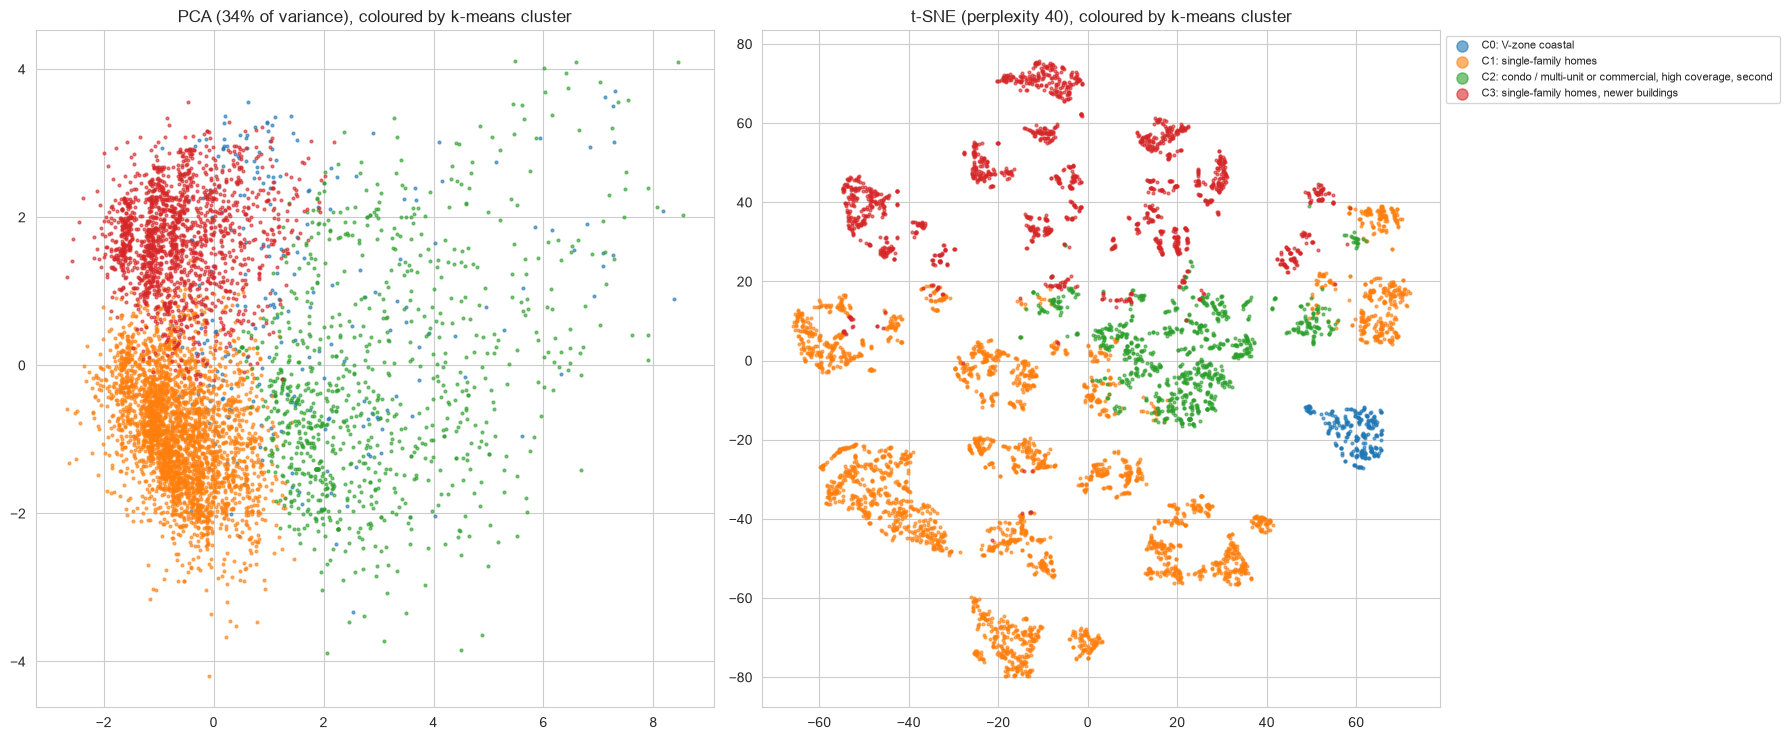

In [14]:
plot_index = np.random.default_rng(SEED).choice(len(scaled_sample), 6000, replace=False)
plot_data = scaled_sample[plot_index]
plot_rows = cluster_sample.iloc[plot_index].reset_index(drop=True)
pca_2d = PCA(n_components=2, random_state=SEED).fit(scaled_sample)
pca_points = pca_2d.transform(plot_data)
tsne_points = TSNE(n_components=2, perplexity=40, init='pca', learning_rate='auto', random_state=SEED).fit_transform(plot_data)
plot_rows[['pca_1', 'pca_2']] = pca_points
plot_rows[['tsne_1', 'tsne_2']] = tsne_points

palette = dict(zip(sorted(plot_rows['cluster'].unique()), sns.color_palette('tab10', CHOSEN_K)))
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, (x_column, y_column, title) in zip(axes, [('pca_1', 'pca_2', f'PCA ({pca_2d.explained_variance_ratio_.sum() * 100:.0f}% of variance)'),
                                                 ('tsne_1', 'tsne_2', 't-SNE (perplexity 40)')]):
    for cluster, group in plot_rows.groupby('cluster'):
        ax.scatter(group[x_column], group[y_column], s=4, alpha=0.6, color=palette[cluster], label=cluster_names[cluster][:60])
    ax.set_title(f'{title}, coloured by k-means cluster')
axes[1].legend(markerscale=4, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_pca_tsne_by_cluster.png', dpi=110)
plt.show()

**Reading the t-SNE.** t-SNE shows many small islands. Each island is one "corner" of the 0/1 flags (for
example: post-FIRM, elevated, primary residence, no basement). The k-means clusters are **unions of islands**, and
each cluster occupies its own part of the map: C3 (newer, post-FIRM single-family homes) at the top, C1 (older,
pre-FIRM single-family homes) in the lower half, C2 (condo / multi-unit / commercial) in the centre right and C0
(V-zone) as one separate island on the right. PCA, being linear, shows C3 and C1 as two touching clouds and spreads
C2 along PC1; C0 is hidden inside the other clouds.

## 7.0 Does the t-SNE picture depend on the perplexity?

Perplexity is roughly the number of neighbours each point "pays attention to". Small values show fine local detail,
large values show broader structure. If the islands and the cluster colours look similar at 10, 40 and 100, the
picture is not an accident of one setting.

**Reading the panel (figure below).** The main picture holds at all three values: C0 (V-zone) is always one separate
island, C1 and C3 always sit in different halves of the map, and C2 is always a central group. What changes is the
detail: at perplexity 10 the map breaks into many tiny fragments, at 100 the islands merge into fewer, bigger
blocks. So the cluster layout is robust; the exact number and shape of the islands is not.

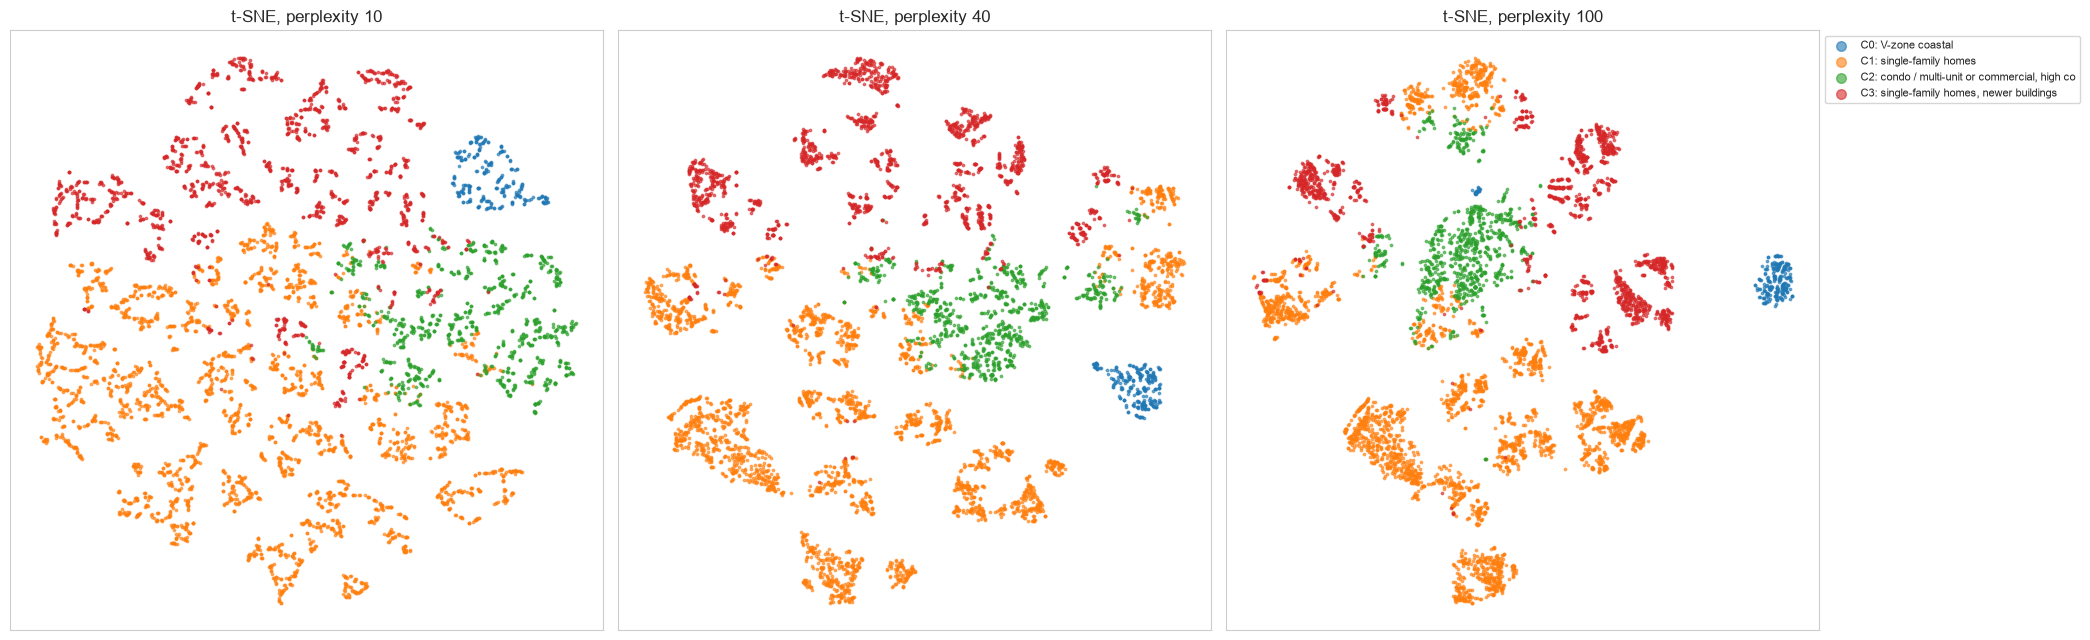

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, perplexity in zip(axes, [10, 40, 100]):
    if perplexity == 40:
        points = tsne_points
    else:
        points = TSNE(n_components=2, perplexity=perplexity, init='pca', learning_rate='auto', random_state=SEED).fit_transform(plot_data)
    for cluster, group_index in plot_rows.groupby('cluster').groups.items():
        ax.scatter(points[group_index, 0], points[group_index, 1], s=3, alpha=0.6, color=palette[cluster], label=cluster_names[cluster][:45])
    ax.set_title(f't-SNE, perplexity {perplexity}')
    ax.set_xticks([])
    ax.set_yticks([])
axes[2].legend(markerscale=4, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_tsne_perplexity_panel.png', dpi=100)
plt.show()

## 7.1 Now colour the same t-SNE map by the outcomes

The outcomes were **not** used to build this map. If paid or large-loss claims gather in some regions,
building and policy facts carry information about the outcome.

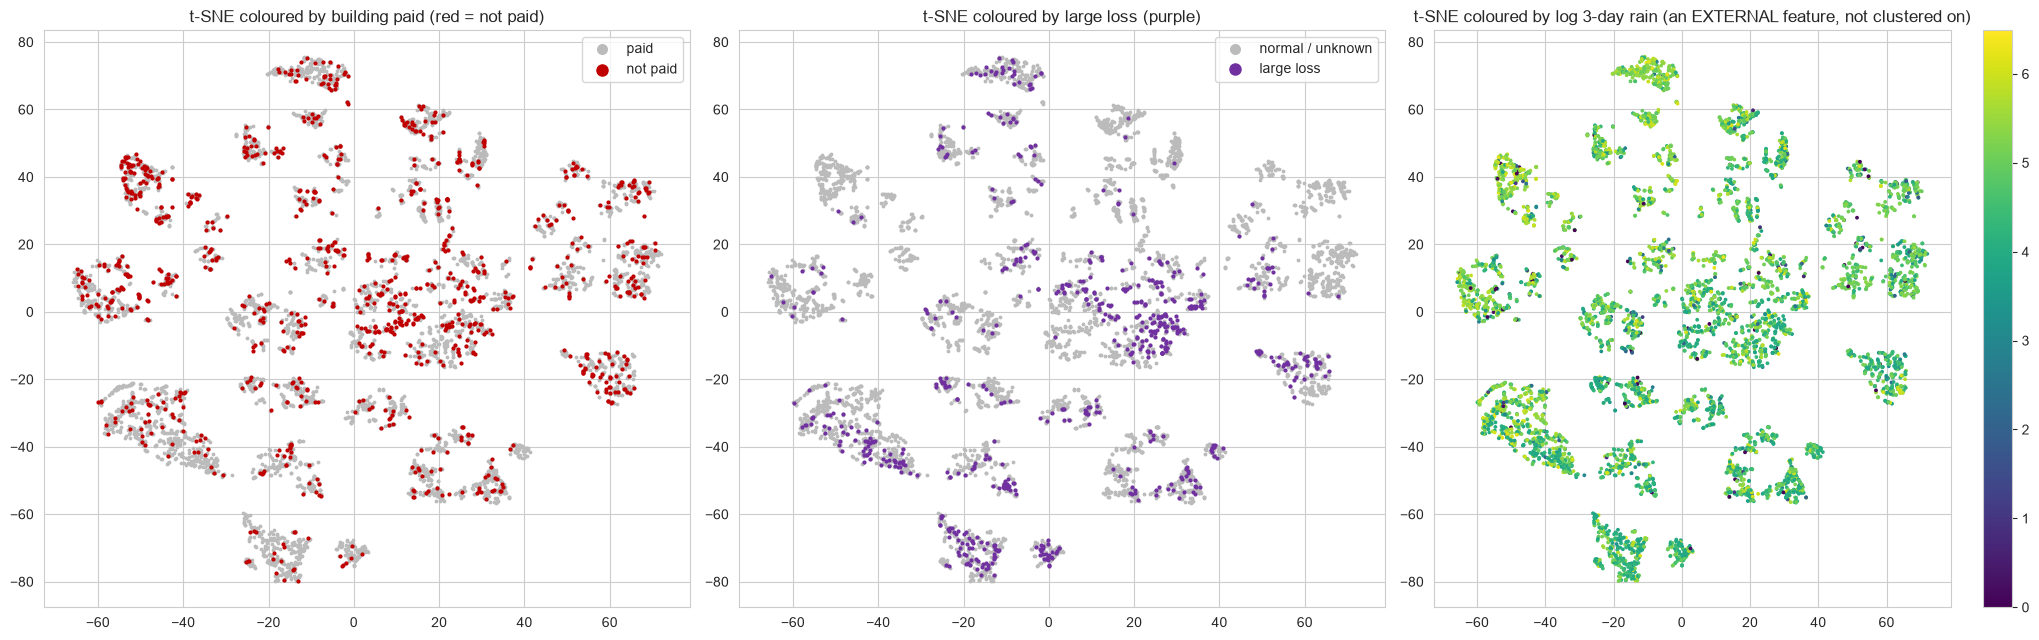

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
not_paid = plot_rows['building_paid_flag'] == 0
axes[0].scatter(plot_rows.loc[~not_paid, 'tsne_1'], plot_rows.loc[~not_paid, 'tsne_2'], s=3, color='#bbbbbb', label='paid')
axes[0].scatter(plot_rows.loc[not_paid, 'tsne_1'], plot_rows.loc[not_paid, 'tsne_2'], s=4, color='#C00000', label='not paid')
axes[0].set_title('t-SNE coloured by building paid (red = not paid)')
axes[0].legend(markerscale=4)
large = plot_rows['large_loss_flag'] == 1
axes[1].scatter(plot_rows.loc[~large, 'tsne_1'], plot_rows.loc[~large, 'tsne_2'], s=3, color='#bbbbbb', label='normal / unknown')
axes[1].scatter(plot_rows.loc[large, 'tsne_1'], plot_rows.loc[large, 'tsne_2'], s=4, color='#7030A0', label='large loss')
axes[1].set_title('t-SNE coloured by large loss (purple)')
axes[1].legend(markerscale=4)
scatter = axes[2].scatter(plot_rows['tsne_1'], plot_rows['tsne_2'], s=3, c=np.log1p(plot_rows['rain_3day_mm']), cmap='viridis')
axes[2].set_title('t-SNE coloured by log 3-day rain (an EXTERNAL feature, not clustered on)')
plt.colorbar(scatter, ax=axes[2])
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_tsne_by_outcome.png', dpi=110)
plt.show()

**Reading the outcome maps.** Unpaid claims (red) are spread over almost every island. Large losses (purple)
gather in the centre and lower half of the map, where the multi-unit / commercial policies (C2) and the older
single-family homes (C1) are, and are rare in the upper part (newer post-FIRM homes, C3). Rain is spread over the
whole map: the building/policy groups do not know about the storm. This is why RQ1 and RQ2 needed the external data.

---
# Section 8: An Autoencoder Instead of PCA (Lecture 16)

An autoencoder is a neural network trained to **copy its input to its output** through a narrow middle layer
(the bottleneck). To copy well, the bottleneck must learn a compressed code. Unlike PCA, the code can be
non-linear. We use `MLPRegressor` with layers 14 -> 8 -> 3 -> 8 -> 14 and read the 3-number middle layer.

In [17]:
autoencoder = MLPRegressor(hidden_layer_sizes=(8, 3, 8), activation='tanh', max_iter=300, early_stopping=True, random_state=SEED)
autoencoder.fit(scaled_sample, scaled_sample)


def encode(model, data):
    """Run the data through the first half of the network (input -> 8 -> 3)."""
    hidden = data
    for layer_index in range(2):
        hidden = np.tanh(hidden @ model.coefs_[layer_index] + model.intercepts_[layer_index])
    return hidden


latent_codes = encode(autoencoder, scaled_sample)
reconstruction_error = ((autoencoder.predict(scaled_sample) - scaled_sample) ** 2).mean()
pca_3 = PCA(n_components=3).fit(scaled_sample)
pca_error = ((pca_3.inverse_transform(pca_3.transform(scaled_sample)) - scaled_sample) ** 2).mean()
print(f'Reconstruction error with a 3-number code: autoencoder {reconstruction_error:.3f}, PCA {pca_error:.3f}')

latent_labels = KMeans(n_clusters=CHOSEN_K, n_init=20, random_state=SEED).fit_predict(latent_codes)
print(f'Silhouette of k-means in the latent space: {silhouette_score(latent_codes, latent_labels, sample_size=8000, random_state=SEED):.3f}')
print(f'Agreement with clusters in the original space (ARI): {adjusted_rand_score(kmeans_final.labels_, latent_labels):.3f}')

Reconstruction error with a 3-number code: autoencoder 0.285, PCA 0.553


Silhouette of k-means in the latent space: 0.519
Agreement with clusters in the original space (ARI): 0.440


---
# Section 9: Only Now: Do the Groups Differ in Outcome?

We now bring back the outcomes, for **all** claims, using the fixed cluster model.

In [18]:
claims['cluster'] = kmeans_final.predict(scaler.transform(claims[CLUSTER_FEATURES]))
claims['cluster_name'] = claims['cluster'].map(cluster_names)
outcome_profile = claims.groupby('cluster_name').agg(
    claims=('id', 'size'), building_paid_rate=('building_paid_flag', 'mean'), large_loss_rate=('large_loss_flag', 'mean'),
    median_paid_if_paid=('amountPaidOnBuildingClaim', lambda s: s[s > 0].median()),
    median_damage_to_value=('damage_to_value_ratio', 'median'), median_rain_3day=('rain_3day_mm', 'median'))
outcome_profile.round(3).to_csv(TABLE_DIR / '05_rq3_cluster_outcomes.csv')
print(outcome_profile.round(3).to_string())


def cramers_v(table):
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


association_rows = []
for grouping in ['cluster', 'flood_zone_group', 'occupancy_group']:
    for outcome in ['building_paid_flag', 'large_loss_flag']:
        data = claims.dropna(subset=[outcome])
        table = pd.crosstab(data[grouping], data[outcome])
        association_rows.append({'grouping': grouping, 'outcome': outcome, 'n_groups': table.shape[0],
                                 'chi2_p_value': chi2_contingency(table)[1], 'cramers_V': cramers_v(table)})
association_table = pd.DataFrame(association_rows)
association_table.round(4).to_csv(TABLE_DIR / '05_rq3_cluster_vs_outcome_association.csv', index=False)
print('\nHow strongly does each grouping separate the outcomes? (Cramer\'s V: 0 = not at all, 1 = perfectly)')
print(association_table.round(4).to_string(index=False))

                                                                             claims  building_paid_rate  large_loss_rate  median_paid_if_paid  median_damage_to_value  median_rain_3day
cluster_name                                                                                                                                                                           
C0: V-zone coastal                                                             9820               0.789            0.183            29435.585                   0.069            85.587
C1: single-family homes                                                      135250               0.872            0.117            50785.320                   0.258            98.295
C2: condo / multi-unit or commercial, high coverage, second homes / rentals   37454               0.793            0.269            72344.825                   0.103           123.563
C3: single-family homes, newer buildings                                      70


How strongly does each grouping separate the outcomes? (Cramer's V: 0 = not at all, 1 = perfectly)
        grouping            outcome  n_groups  chi2_p_value  cramers_V
         cluster building_paid_flag         4           0.0     0.1139
         cluster    large_loss_flag         4           0.0     0.2035
flood_zone_group building_paid_flag         6           0.0     0.1097
flood_zone_group    large_loss_flag         6           0.0     0.1198
 occupancy_group building_paid_flag         7           0.0     0.1958
 occupancy_group    large_loss_flag         7           0.0     0.2188


**Reading Cramer's V.** With 250,000 claims every p-value is tiny, so significance alone means nothing. Cramer's
V gives the **size** of the association. For large loss, the 4 clusters (V = 0.204) beat flood zone (0.120) but not
occupancy type alone (0.219). For payment, the clusters (0.114) are similar to flood zone (0.110) and weaker than
occupancy (0.196). The clusters therefore carry outcome information, but one simple column carries as much.

**The profile is still informative.** Older pre-FIRM single-family homes (C1) have the highest damage relative to
value (median 26% vs 5% for newer post-FIRM homes, C3) and a large-loss rate of 11.7% vs 5.5%. Newer post-FIRM homes
(C3) are paid least often (78.3%): built to code, they often have damage below the deductible. Condo / multi-unit /
commercial (C2) has the highest large-loss rate (26.9%), mostly because the insured amounts are larger. V-zone
policies (C0) are paid 78.9% of the time and 18.3% are large.

---
# Section 10: Adding Neighbourhood Context: Do the Groups Get More Meaningful?

The project's progression applied to clustering: we add ACS income, home value and NRI coastal flood risk to
the clustering features and check if the groups now separate outcomes better.

In [19]:
CONTEXT_CLUSTER_FEATURES = CLUSTER_FEATURES + ['acs_median_household_income', 'acs_median_home_value', 'nri_coastal_flood_risk_score', 'coast_distance_km']
context_data = claims[CONTEXT_CLUSTER_FEATURES].copy()
for column in ['acs_median_household_income', 'acs_median_home_value', 'coast_distance_km']:
    context_data[column] = np.log1p(context_data[column])
context_scaler = StandardScaler().fit(context_data.loc[cluster_sample.index.intersection(context_data.index)])
context_sample = context_scaler.transform(context_data.sample(20_000, random_state=SEED))
context_model = KMeans(n_clusters=CHOSEN_K, n_init=20, random_state=SEED).fit(context_sample)
claims['context_cluster'] = context_model.predict(context_scaler.transform(context_data))
progression_rows = []
for grouping in ['cluster', 'context_cluster']:
    for outcome in ['building_paid_flag', 'large_loss_flag']:
        data = claims.dropna(subset=[outcome])
        progression_rows.append({'clustering': 'NFIP building+policy' if grouping == 'cluster' else '+ ACS, NRI, coast distance',
                                 'outcome': outcome, 'cramers_V': cramers_v(pd.crosstab(data[grouping], data[outcome]))})
progression_table = pd.DataFrame(progression_rows).round(4)
progression_table.to_csv(TABLE_DIR / '05_rq3_progression.csv', index=False)
print(f'Silhouette with context features: {silhouette_score(context_sample, context_model.labels_, sample_size=8000, random_state=SEED):.3f}')
print(progression_table.to_string(index=False))

Silhouette with context features: 0.129
                clustering            outcome  cramers_V
      NFIP building+policy building_paid_flag     0.1139
      NFIP building+policy    large_loss_flag     0.2035
+ ACS, NRI, coast distance building_paid_flag     0.1235
+ ACS, NRI, coast distance    large_loss_flag     0.2507


In [20]:
results_rq3 = {'chosen_k': CHOSEN_K, 'choice_reason': choice_reason, 'silhouette_gap_best_k': silhouette_gap_best_k,
               'gap_rule_k': gap_rule_k, 'k_table': comparison.round(4).to_dict('records'), 'cluster_names': cluster_names,
               'seed_ARI': seed_ari, 'sample_ARI': sample_ari, 'association': association_table.to_dict('records'),
               'progression': progression_table.to_dict('records')}
json.dump(results_rq3, open(TABLE_DIR / '05_rq3_results.json', 'w'), indent=2, default=float)

---
# Section 11: Column-drop experiment: do the clusters survive without some columns?

k-means is sensitive to **which columns go in**. If one group of columns (for example the coverage amounts, which
have a wide spread) decides the clusters, the "groups" are only a picture of those columns. So we drop columns on
purpose (an **ablation**) and run k-means again at the chosen k = 4, on the same 20,000-claim sample and with the
same seed:

| Version | Columns |
|---|---|
| (a) all features | the 14 columns of Section 1 (the main solution) |
| (b) without coverage amounts | drop building and contents coverage (12 columns) |
| (c) building only | building facts and where the building sits on the flood map (9 columns) |
| (d) policy only | coverage, deductible, policy tenure, primary residence (5 columns) |

For each version we report the silhouette at k = 4, whether it beats **all 20** column-shuffled datasets (as in
Section 2.2), the k with the best silhouette between 2 and 10, and the **ARI** between its labels and the main k = 4
labels (1 = the same groups, 0 = chance). To see if the **named** clusters survive, we also check, for each main
cluster, which share of its claims end up together in one new cluster.

In [21]:
COVERAGE_COLUMNS = ['log_building_coverage', 'log_contents_coverage']
BUILDING_COLUMNS = ['postFIRMConstructionIndicator', 'building_age_at_loss', 'number_of_floors', 'elevatedBuildingIndicator',
                    'has_basement', 'is_single_family', 'log_number_of_units', 'in_special_flood_hazard_area', 'in_V_zone']
POLICY_COLUMNS = ['log_building_coverage', 'log_contents_coverage', 'log_deductible', 'policy_tenure_years', 'primaryResidenceIndicator']
column_drop_versions = {
    '(a) all features': CLUSTER_FEATURES,
    '(b) without coverage amounts': [column for column in CLUSTER_FEATURES if column not in COVERAGE_COLUMNS],
    '(c) building only': BUILDING_COLUMNS,
    '(d) policy only': POLICY_COLUMNS,
}
assert set(BUILDING_COLUMNS) | set(POLICY_COLUMNS) == set(CLUSTER_FEATURES)
main_labels = kmeans_final.labels_
column_drop_rows, cluster_match_rows = [], []
for version_name, columns in column_drop_versions.items():
    version_scaled = StandardScaler().fit_transform(cluster_sample[columns])
    version_model = KMeans(n_clusters=CHOSEN_K, n_init=20, random_state=SEED).fit(version_scaled)
    version_silhouette = silhouette_score(version_scaled, version_model.labels_, sample_size=8000, random_state=SEED)
    # best k between 2 and 10 by silhouette (same settings as Section 2.1)
    silhouette_by_k = {k: silhouette_score(version_scaled, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(version_scaled).labels_,
                                           sample_size=8000, random_state=SEED) for k in range(2, 11)}
    # 20 column-shuffled datasets at k = 4 (as in Section 2.2)
    noise_rng = np.random.default_rng(SEED)
    noise_silhouettes = []
    for repeat in range(NOISE_REPEATS):
        shuffled = version_scaled.copy()
        for column_index in range(shuffled.shape[1]):
            shuffled[:, column_index] = noise_rng.permutation(shuffled[:, column_index])
        noise_model = KMeans(n_clusters=CHOSEN_K, n_init=10, random_state=SEED).fit(shuffled)
        noise_silhouettes.append(silhouette_score(shuffled, noise_model.labels_, sample_size=8000, random_state=SEED))
    noise_silhouettes = np.array(noise_silhouettes)
    column_drop_rows.append({'version': version_name, 'n_columns': len(columns), 'silhouette_k4': version_silhouette,
                             'noise_mean_k4': noise_silhouettes.mean(), 'noise_max_k4': noise_silhouettes.max(),
                             'beats_all_20_noise': bool(version_silhouette > noise_silhouettes.max()),
                             'best_k_by_silhouette': max(silhouette_by_k, key=silhouette_by_k.get),
                             'best_silhouette_2_to_10': max(silhouette_by_k.values()),
                             'ARI_vs_main_k4': adjusted_rand_score(main_labels, version_model.labels_)})
    overlap = pd.crosstab(main_labels, version_model.labels_)
    for main_cluster, counts in overlap.iterrows():
        cluster_match_rows.append({'version': version_name, 'main_cluster': cluster_names[main_cluster],
                                   'main_cluster_claims': int(counts.sum()),
                                   'share_kept_together_%': 100 * counts.max() / counts.sum(),
                                   'matching_new_cluster_purity_%': 100 * counts.max() / overlap[counts.idxmax()].sum()})
column_drop_table = pd.DataFrame(column_drop_rows).round(4)
cluster_match_table = pd.DataFrame(cluster_match_rows).round(1)
column_drop_table.to_csv(TABLE_DIR / '05_rq3_column_drop.csv', index=False)
cluster_match_table.to_csv(TABLE_DIR / '05_rq3_column_drop_cluster_match.csv', index=False)
print(column_drop_table.to_string(index=False))
print('\nDo the named clusters survive? Share of each main cluster kept together in one new cluster,')
print('and how pure that new cluster is (share of it that comes from the main cluster):')
print(cluster_match_table.pivot(index='main_cluster', columns='version', values='share_kept_together_%').to_string())
print()
print(cluster_match_table.pivot(index='main_cluster', columns='version', values='matching_new_cluster_purity_%').to_string())

                     version  n_columns  silhouette_k4  noise_mean_k4  noise_max_k4  beats_all_20_noise  best_k_by_silhouette  best_silhouette_2_to_10  ARI_vs_main_k4
            (a) all features         14         0.1748         0.1192        0.1490                True                     2                   0.2535          1.0000
(b) without coverage amounts         12         0.2045         0.1405        0.1659                True                     2                   0.2544          0.9159
           (c) building only          9         0.2940         0.2232        0.2878                True                    10                   0.4237          0.8406
             (d) policy only          5         0.3232         0.2767        0.2819                True                    10                   0.3749          0.1559

Do the named clusters survive? Share of each main cluster kept together in one new cluster,
and how pure that new cluster is (share of it that comes from the main c

**What this shows.**

- **Without the two coverage amounts (12 columns) the clusters hardly change:** ARI 0.92 with the main k = 4 labels,
  and every named group stays together (96-100% of its claims in one new cluster). Silhouette 0.205 vs noise 0.141
  (max 0.166), so it still beats all 20 noise sets. Coverage is **not** what builds the groups.
- **Building columns alone (9 columns) give almost the same four groups:** ARI 0.84. V-zone, older and newer
  single-family homes survive (98-100% kept together). The condo / multi-unit group is the weak one: only 63% of it
  stays together, because part of what defines it is high coverage. Silhouette 0.294 beats the noise mean (0.223),
  but only just beats the best noise set (0.288), so the margin is thin.
- **Policy columns alone (5 columns) do not find the same groups:** ARI 0.16. The V-zone group disappears (40% kept
  together, purity 8%), and no group keeps more than 69% of its claims. Its silhouette (0.323) looks high, but noise
  data with only five columns also scores high (0.277 to 0.282), so the number is not comparable.
- With every feature set the highest raw silhouette is at k = 2 (all features) or k = 10 (building only, policy only),
  not at k = 4. This agrees with Section 2.1: k = 4 is a design choice, not the statistical optimum.

In short, **the named clusters are building clusters.** Building facts carry the structure; policy facts add
mostly the condo / high-coverage detail.

---
## The numbers behind the answer

Read back from the saved tables (`tables/05_*`). The answer text below uses these numbers, rounded.

In [22]:
results_saved = json.load(open(TABLE_DIR / '05_rq3_results.json'))
k_saved = pd.read_csv(TABLE_DIR / '05_rq3_k_selection.csv').set_index('k')
outcomes_saved = pd.read_csv(TABLE_DIR / '05_rq3_cluster_outcomes.csv')
association_saved = pd.read_csv(TABLE_DIR / '05_rq3_cluster_vs_outcome_association.csv')
progression_saved = pd.read_csv(TABLE_DIR / '05_rq3_progression.csv')
chosen = results_saved['chosen_k']
rows = [('chosen k', chosen, '05_rq3_results.json'), ('reason', results_saved['choice_reason'], '05_rq3_results.json'),
        ('k with largest silhouette gap over noise', results_saved['silhouette_gap_best_k'], '05_rq3_k_selection'),
        ('k by Tibshirani gap rule', results_saved['gap_rule_k'], '05_rq3_k_selection')]
for k in [2, 3, 4, 5, 6]:
    r = k_saved.loc[k]
    rows.append((f'k={k}: silhouette vs noise mean (SD), gap, z, beats all 20', f"{r['silhouette']:.3f} vs {r['noise_mean']:.3f} ({r['noise_std']:.3f}), "
                 f"{r['real_minus_noise']:+.3f}, z={r['z_vs_noise']:.1f}, {bool(r['beats_all_20_noise'])}", '05_rq3_k_selection'))
rows += [('seed ARI (5 other seeds)', ', '.join(f'{v:.2f}' for v in results_saved['seed_ARI']), '05_rq3_results.json'),
         ('ARI between two samples', results_saved['sample_ARI'], '05_rq3_results.json')]
for _, r in outcomes_saved.iterrows():
    rows.append((f"{r['cluster_name'][:70]}", f"claims {int(r['claims']):,}, paid {r['building_paid_rate']:.3f}, large {r['large_loss_rate']:.3f}, "
                 f"damage/value {r['median_damage_to_value']:.3f}", '05_rq3_cluster_outcomes'))
for _, r in association_saved.iterrows():
    rows.append((f"Cramer's V {r['grouping']} vs {r['outcome']}", r['cramers_V'], '05_rq3_cluster_vs_outcome_association'))
for _, r in progression_saved.iterrows():
    rows.append((f"Cramer's V {r['clustering']} vs {r['outcome']}", r['cramers_V'], '05_rq3_progression'))
rows += [('autoencoder vs PCA reconstruction error (3 numbers)', f'{reconstruction_error:.3f} vs {pca_error:.3f}', 'this notebook'),
         ('ARI latent-space clusters vs original', adjusted_rand_score(kmeans_final.labels_, latent_labels), 'this notebook'),
         ('Ward vs k-means ARI', pd.DataFrame(linkage_rows).set_index('linkage').loc['ward', 'ARI_vs_kmeans'], 'this notebook')]
answer_numbers = show_answer_numbers(rows, '05_rq3')

                                                              quantity                                                                                       value                                source
                                                              chosen k                                                                                           4                   05_rq3_results.json
                                                                reason k = 4 kept by design: its silhouette 0.175 beats all 20 noise datasets (max 0.149, z = 3.2)                   05_rq3_results.json
                              k with largest silhouette gap over noise                                                                                           2                    05_rq3_k_selection
                                              k by Tibshirani gap rule                                                                                           7                    05_rq3_k_selec

---
# Research Question -> Answer

> **RQ3. If we ignore the damage outcome, do the building and policy features form groups that mean something?**

**The three questions from Lectures 08/10** (numbers from the `answer_numbers` table above):

| Question | Answer |
|---|---|
| Silhouette clearly better than random data of the same shape? | Yes for k >= 4. k = 4: 0.175 vs 0.119 +/- 0.017 over 20 shuffled datasets (max 0.149, z = 3.2). k = 2 and 3 do not beat every noise set |
| Which k do the criteria pick? | Largest silhouette gap: k = 2 (not robust to noise). Gap statistic rule: k = 7 (no clear elbow). Best silhouette: k = 6 (0.204). **We keep k = 4** as a design choice: it is real structure and easy to use, but not the statistical optimum |
| Same structure with another seed and another sample? | **Only partly.** Seed ARI 1.00 / 0.62 / 0.62 / 0.93 / 0.62, sample ARI 0.98. k-means finds two competing 4-group solutions |
| Can we name the clusters? | Yes: older pre-FIRM single-family homes (C1, 53%), newer post-FIRM single-family homes (C3, 28%), condo / multi-unit / commercial with high coverage (C2, 15%), V-zone coastal (C0, 4%) |

**Answer: yes, there are real, nameable groups, but they describe *what is insured*, not *what will happen*.**
- The groups match known market segments, and their silhouette is above every noise set for k >= 4. But the
  structure is weak (silhouette 0.17-0.25 for any k; 0.254 at k = 2), the "right" k is not clear (2, 4, 6 or 7 depending on the
  rule), and k = 4 is only partly stable across seeds. Hierarchical Ward linkage agrees only moderately
  (ARI 0.32), and DBSCAN finds no density-separated groups (the flags make "corners", not blobs).
- The autoencoder compresses the 14 features better than PCA (error 0.29 vs 0.55 with 3 numbers) and its grouping
  agrees only partly with the original one (ARI 0.44). The structure depends on the representation.
- Checked against outcomes **afterwards**, the groups differ: large-loss rate 5.5% (newer post-FIRM homes) to 26.9%
  (multi-unit), damage-to-value 5% to 26%. Cramer's V with large loss is 0.20, better than flood zone (0.12) but
  not better than occupancy alone (0.22).
- The t-SNE maps show why the link is only moderate: rain and storm exposure are spread across all groups. The
  map layout is the same at perplexity 10, 40 and 100. Adding neighbourhood and coast context to the clustering
  raises Cramer's V with large loss from 0.204 to 0.251.
- **Use:** the clusters are a good way to *describe* the portfolio and the "older pre-FIRM home" risk, but not a
  prediction tool on their own.